# Projeto 2 — Task 1: séries temporais, análise exploratória e enquadramento da previsão

**Mineração de Dados 2026/27 · Previsão *day-ahead* da procura de carregamento de veículos elétricos**

**Pergunta do projeto.** Em que medida o histórico de carregamentos, os padrões temporais e outra informação relevante permitem prever, com exatidão, o número de sessões de carregamento que **começam em cada uma das próximas 24 horas**, ao nível da rede e de cada um dos três distritos?

**Objetivo desta Task.** Transformar as transações em séries temporais coerentes, compreender as suas características e **fixar o protocolo de previsão e avaliação antes de qualquer modelo**. A Task não treina modelos; só avalia *baselines*, para validar o próprio protocolo.

**Estrutura**

1. Dados e auditoria de qualidade
2. Construção das séries horárias
3. Análise exploratória (nível, tendência, sazonalidade, distritos, meteorologia, estacionariedade)
4. Formulação operacional da previsão (emissão, estratégia, informação disponível, ausência de *leakage*)
5. Protocolo de avaliação (partição temporal, métricas, *baselines*)
6. Síntese e ficheiros exportados

**Regra de rigor.** O período de teste final (2021-10-01 a 2021-12-31) é definido logo na configuração e **não é usado em nenhuma decisão de modelação**. A auditoria de qualidade e os gráficos de visão geral cobrem todo o período; as análises que sustentam escolhas (sazonalidade, ACF, estacionariedade, efeitos de calendário, meteorologia, período sazonal do MASE) usam **só o desenvolvimento**.

## 0. Configuração

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import acf, adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

CANDIDATES = [Path("Charging_Data.csv"), Path("../Charging_Data.csv"), Path("../MINDD_Project/Charging_Data.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Charging_Data.csv não encontrado em: " + ", ".join(map(str, CANDIDATES)))

DISTRICTS = ["Nanhu", "Tongxiang", "Xiuzhou"]
LEVELS = ["Network"] + DISTRICTS
HORIZONS = np.arange(1, 25)

SERIES_START = pd.Timestamp("2020-01-01 00:00")
SERIES_END = pd.Timestamp("2021-12-31 23:00")
HOURS = pd.date_range(SERIES_START, SERIES_END, freq="h")

# Teste final fixado já aqui; as análises de decisão usam apenas o desenvolvimento.
TEST_START = pd.Timestamp("2021-10-01 00:00")
DEV_END = TEST_START - pd.Timedelta(hours=1)
# Regime "regular": depois do colapso do início de 2020 (ver secção 3.1).
REGULAR_FROM = pd.Timestamp("2020-04-01 00:00")
# Postos que deixam de registar sessões (secção 3.1); a data é o último dia com registos.
CAPACITY_BREAKS = {"Nanhu": ["2021-09-28", "2021-12-13"]}

# Feriados oficiais (avisos do Conselho de Estado). Lista inserida manualmente: validar antes de modelar.
HOLIDAY_RANGES = [
    ("2020-01-01", "2020-01-01", "Ano Novo"),
    ("2020-01-24", "2020-02-02", "Festival da Primavera (prolongado)"),
    ("2020-04-04", "2020-04-06", "Qingming"),
    ("2020-05-01", "2020-05-05", "Dia do Trabalhador"),
    ("2020-06-25", "2020-06-27", "Dragon Boat"),
    ("2020-10-01", "2020-10-08", "Dia Nacional + Meio-Outono"),
    ("2021-01-01", "2021-01-03", "Ano Novo"),
    ("2021-02-11", "2021-02-17", "Festival da Primavera"),
    ("2021-04-03", "2021-04-05", "Qingming"),
    ("2021-05-01", "2021-05-05", "Dia do Trabalhador"),
    ("2021-06-12", "2021-06-14", "Dragon Boat"),
    ("2021-09-19", "2021-09-21", "Meio-Outono"),
    ("2021-10-01", "2021-10-07", "Dia Nacional"),
]
HOLIDAY_DAYS = pd.DatetimeIndex(
    [d for a, b, _ in HOLIDAY_RANGES for d in pd.date_range(a, b, freq="D")]
)
print("Ficheiro de dados:", DATA_PATH.resolve())

Ficheiro de dados: /Users/ctw03584/Documents/ISEP/mindd/MINDD_Project/Charging_Data.csv


## 1. Dados e auditoria de qualidade

Cada linha é uma transação de carregamento. Para este projeto interessa o **instante de início da sessão** (`Start Time`), o **distrito** e o **posto**. A meteorologia (temperatura, humidade, precipitação) é analisada à parte. As colunas de causa de término (`end_cause`, `is_*`) pertenciam ao Projeto 1 e **não são usadas**.

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="latin1")
raw.columns = [c.strip() for c in raw.columns]
assert raw.columns[13].startswith("Temperature")  # o símbolo de grau vem corrompido na codificação
raw = raw.rename(columns={raw.columns[13]: "Temperature"})

loc_raw = raw["Location Information"]
n_loc_whitespace = int(loc_raw.ne(loc_raw.str.strip()).sum())
raw["Location Information"] = loc_raw.str.strip()
for col in ["Order creation time", "Start Time", "End Time", "Payment time"]:
    raw[col] = pd.to_datetime(raw[col].str.strip(), errors="coerce")

sessions = raw.rename(columns={
    "Start Time": "start", "End Time": "end", "District Name": "district",
    "Charging Post ID": "post", "Location Information": "location",
    "Transaction power/kwh": "kwh", "Temperature": "temp",
    "Relative Humidity(%)": "rh", "Precipitation(mm)": "prec",
})[["start", "end", "district", "post", "location", "kwh", "temp", "rh", "prec"]].copy()
sessions["duration_min"] = (sessions["end"] - sessions["start"]).dt.total_seconds() / 60

audit = pd.Series({
    "Registos (sessões)": len(raw),
    "Colunas no ficheiro": raw.shape[1],
    "Valores em falta (qualquer coluna)": int(raw.isna().sum().sum()),
    "Linhas duplicadas (todas as colunas)": int(raw.duplicated().sum()),
    "Duplicados (posto, início)": int(sessions.duplicated(["post", "start"]).sum()),
    "Fim anterior ao início": int((sessions["end"] < sessions["start"]).sum()),
    "Valores de localização com espaços/tabs": n_loc_whitespace,
    "Primeiro início": sessions["start"].min(),
    "Último início": sessions["start"].max(),
    "Sessões antes de 2020-01-01": int((sessions["start"] < SERIES_START).sum()),
})
display(audit.to_frame("valor"))

district_tbl = sessions.groupby("district").agg(
    postos=("post", "nunique"), sessoes=("start", "size"),
    primeira=("start", "min"), ultima=("start", "max"),
)
district_tbl["% sessões"] = (district_tbl["sessoes"] / len(sessions) * 100).round(1)
display(district_tbl)

weather_range = sessions[["temp", "rh", "prec", "kwh", "duration_min"]].describe().loc[["min", "50%", "max"]]
display(weather_range)

,valor
Registos (sessões),441077
Colunas no ficheiro,24
Valores em falta (qualquer coluna),0
Linhas duplicadas (todas as colunas),0
"Duplicados (posto, início)",0
Fim anterior ao início,0
Valores de localização com espaços/tabs,18370
Primeiro início,2019-12-31 21:27:03
Último início,2021-12-31 23:52:14
Sessões antes de 2020-01-01,17


,postos,sessoes,primeira,ultima,% sessões
district,,,,,
Nanhu,20,71449,2020-01-01 01:42:01,2021-12-31 23:48:14,16.200
Tongxiang,40,220923,2019-12-31 21:27:03,2021-12-31 23:52:14,50.100
Xiuzhou,32,148705,2019-12-31 21:50:56,2021-12-31 23:40:25,33.700


,temp,rh,prec,kwh,duration_min
min,-3.200,32.000,0.000,0.000,0.000
50%,21.000,76.000,0.000,15.150,33.283
max,33.600,99.000,152.100,117.740,"1,439.133"


**Leitura.** O ficheiro está completo e sem duplicados (sem valores em falta nem fins anteriores aos inícios). Os problemas reais são pequenos e de dois tipos:

- **Formato:** localizações com espaços/tabs (18 370 registos) e timestamps com preenchimento, tratados na leitura; a coluna da temperatura vem com o nome corrompido.
- **Âmbito:** 17 sessões iniciadas a 2019-12-31 ficam fora da série (2020-01-01 a 2021-12-31).

Nanhu tem 20 postos, Tongxiang 40 e Xiuzhou 32 (92 no total).

## 2. Construção das séries horárias

**Definição da variável a prever.** $y_t^{(g)}$ = número de sessões do nível $g$ cujo `Start Time` cai no intervalo $[t, t+1\,\text{h})$. O índice da série é o **início** da hora. O nível *Network* é a soma dos três distritos (coerência hierárquica por construção).

**Preparação.**

- Fuso horário local (UTC+8). A China não tem hora de verão, por isso não há horas duplicadas nem inexistentes.
- A série começa em 2020-01-01 00:00. As sessões de 2019-12-31 (só as últimas horas do dia, em 2 distritos) são um extremo incompleto e ficam de fora.
- A transação só regista **eventos**: uma hora sem registos é uma hora com **procura zero**, não um valor em falta. Constrói-se a grelha horária completa e preenche-se com 0, depois de verificar que isso é plausível.

In [3]:
in_scope = sessions[(sessions["start"] >= SERIES_START) & (sessions["start"] < SERIES_END + pd.Timedelta(hours=1))].copy()
in_scope["hour"] = in_scope["start"].dt.floor("h")
dropped_edge = len(sessions) - len(in_scope)

counts = in_scope.groupby(["hour", "district"]).size().unstack("district", fill_value=0)
hours_with_sessions = in_scope["hour"].nunique()
hourly = counts.reindex(HOURS, fill_value=0)[DISTRICTS].astype(int)
hourly.insert(0, "Network", hourly.sum(axis=1))
hourly.index.name = "hour"

assert len(hourly) == 17544 and hourly.index.is_monotonic_increasing
assert hourly["Network"].sum() == len(in_scope) == len(sessions) - dropped_edge
assert (hourly[DISTRICTS].sum(axis=1) == hourly["Network"]).all()

print(f"Sessões fora do âmbito (antes de {SERIES_START.date()}): {dropped_edge}")
print(f"Horas na grelha: {len(hourly):,} | horas com pelo menos 1 sessão (rede): {hours_with_sessions:,} | horas a zero preenchidas: {len(hourly) - hours_with_sessions:,}")
display(hourly.describe().T)

Sessões fora do âmbito (antes de 2020-01-01): 17
Horas na grelha: 17,544 | horas com pelo menos 1 sessão (rede): 17,064 | horas a zero preenchidas: 480


,count,mean,std,min,25%,50%,75%,max
district,,,,,,,,
Network,"17,544.000",25.140,18.884,0.000,8.000,23.000,39.000,129.000
Nanhu,"17,544.000",4.073,4.212,0.000,1.000,3.000,6.000,47.000
Tongxiang,"17,544.000",12.592,9.936,0.000,4.000,11.000,20.000,73.000
Xiuzhou,"17,544.000",8.476,7.762,0.000,2.000,6.000,13.000,70.000


,horas a zero,% horas a zero,maior sequência (h),sequências >= 24 h,dias sem sessões
nível,,,,,
Network,480,2.740,12,0,0
Nanhu,3582,20.420,29,4,1
Tongxiang,1012,5.770,15,0,0
Xiuzhou,1741,9.920,16,0,0


Horas a zero da rede entre 00h e 07h: 78.1% | em jan-mar 2020: 88.8%


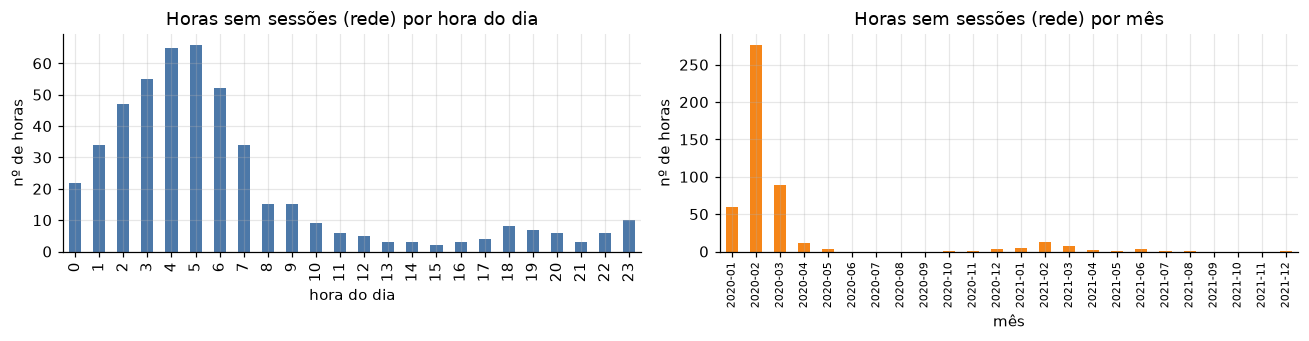

In [4]:
def zero_runs(s):
    z = s.eq(0)
    grp = z.ne(z.shift()).cumsum()
    runs = z.groupby(grp).agg(["first", "size"])
    return runs.loc[runs["first"], "size"]

rows = []
for lv in LEVELS:
    s = hourly[lv]
    r = zero_runs(s)
    rows.append({
        "nível": lv,
        "horas a zero": int(s.eq(0).sum()),
        "% horas a zero": round(s.eq(0).mean() * 100, 2),
        "maior sequência (h)": int(r.max()),
        "sequências >= 24 h": int((r >= 24).sum()),
        "dias sem sessões": int(s.resample("D").sum().eq(0).sum()),
    })
zero_tbl = pd.DataFrame(rows).set_index("nível")
display(zero_tbl)

zh = hourly["Network"].eq(0)
by_hod = zh.groupby(zh.index.hour).sum()
by_month = zh.groupby(zh.index.to_period("M")).sum()
share_night = by_hod.loc[0:7].sum() / by_hod.sum()
share_q1_2020 = by_month.loc["2020-01":"2020-03"].sum() / by_month.sum()
print(f"Horas a zero da rede entre 00h e 07h: {share_night:.1%} | em jan-mar 2020: {share_q1_2020:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
by_hod.plot.bar(ax=ax[0], color="#4C78A8")
ax[0].set(title="Horas sem sessões (rede) por hora do dia", xlabel="hora do dia", ylabel="nº de horas")
by_month.rename(index=str).plot.bar(ax=ax[1], color="#F58518", rot=90)
ax[1].set(title="Horas sem sessões (rede) por mês", xlabel="mês", ylabel="nº de horas")
ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

**Leitura.** As 480 horas a zero da rede **não são falhas**: 78% ocorrem entre as 00h e as 07h e 89% concentram-se em janeiro-março de 2020, quando a procura colapsa (Festival da Primavera e COVID-19). Preenchem-se com 0, que é o valor real da procura. A rede não tem nenhum dia sem sessões. Em Nanhu há 20% de horas a zero e 4 sequências de 24 h ou mais: a procura horária é esparsa (contagens baixas).

In [5]:
# Sensibilidade: sessões sem energia ou com duração <= 1 min (tentativas abortadas) alteram a série?
valid = in_scope[(in_scope["kwh"] > 0) & (in_scope["duration_min"] > 1)]
valid_hourly = valid.groupby("hour").size().reindex(HOURS, fill_value=0)
corr_valid = np.corrcoef(valid_hourly, hourly["Network"])[0, 1]
share_zero_kwh = (in_scope["kwh"] == 0).mean()
share_short = (in_scope["duration_min"] <= 1).mean()
share_removed = 1 - len(valid) / len(in_scope)
mae_diff = (hourly["Network"] - valid_hourly).abs().mean()
print(f"Sessões com 0 kWh: {share_zero_kwh:.1%} | duração <= 1 min: {share_short:.1%} | removidas pelo filtro: {share_removed:.1%}")
print(f"Correlação horária com a série sem essas sessões: {corr_valid:.4f} | diferença média absoluta: {mae_diff:.2f} sessões/hora")

Sessões com 0 kWh: 12.4% | duração <= 1 min: 4.4% | removidas pelo filtro: 12.6%
Correlação horária com a série sem essas sessões: 0.9834 | diferença média absoluta: 3.16 sessões/hora


**Leitura.** As sessões com 0 kWh (12,4%) ou de duração até 1 minuto (4,4%) são plausíveis como tentativas de ligação sem carga. Mantêm-se porque o que se prevê é o **início de sessões**. Retirá-las mudaria a série em apenas 3 sessões/hora em média (correlação 0,98), pelo que a escolha não é crítica.

## 3. Análise exploratória

As secções 3.1 a 3.6 usam o desenvolvimento (até 2021-09-30), exceto onde indicado. Os gráficos de visão geral mostram o teste sombreado, só para contexto.

### 3.1 Nível, tendência e mudanças de regime

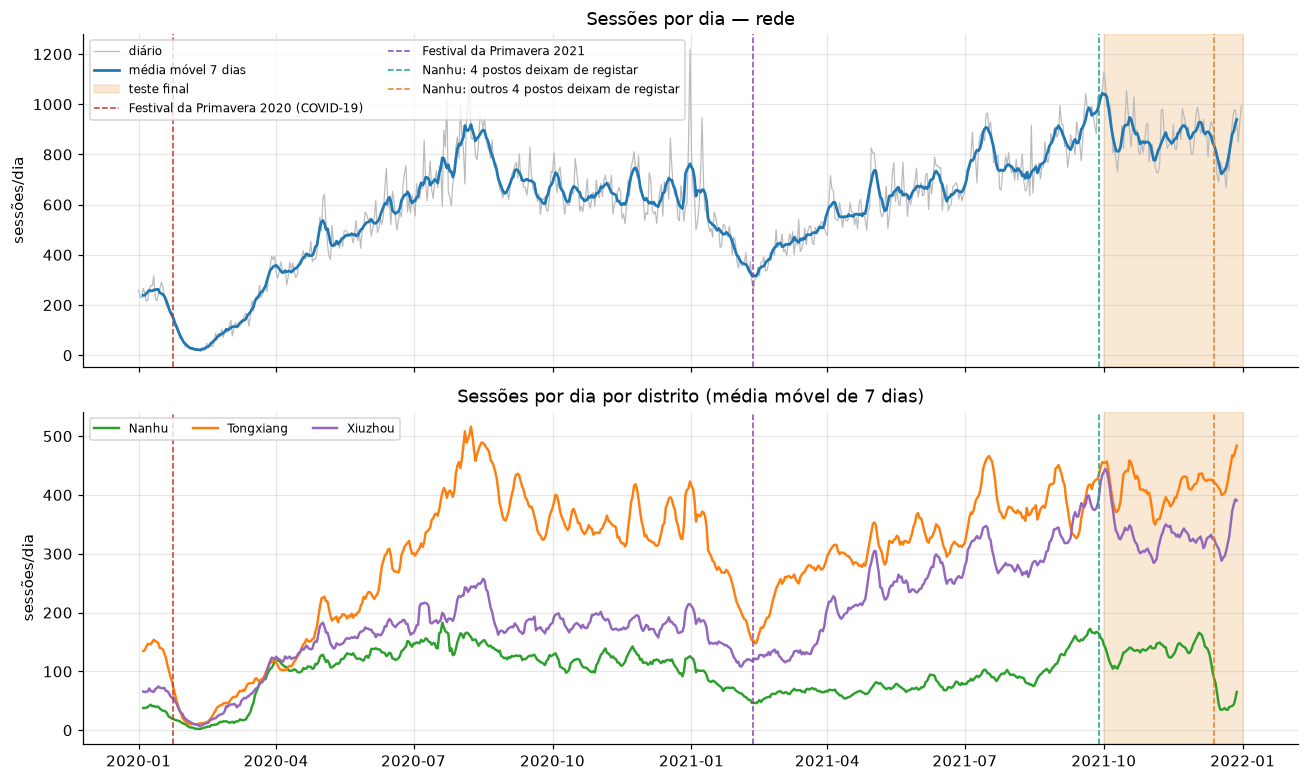

district,Network,Nanhu,Tongxiang,Xiuzhou,Network (var. % homóloga),Nanhu (var. % homóloga),Tongxiang (var. % homóloga),Xiuzhou (var. % homóloga)
trimestre,,,,,,,,
2020Q1,153.800,30.700,72.900,50.200,NaN,NaN,NaN,NaN
2020Q2,480.000,120.700,204.000,155.300,NaN,NaN,NaN,NaN
2020Q3,737.200,140.200,400.300,196.600,NaN,NaN,NaN,NaN
2020Q4,656.100,117.600,356.400,182.200,NaN,NaN,NaN,NaN
2021Q1,464.400,69.200,255.200,140.000,202.000,125.000,250.000,179.000
2021Q2,632.300,71.800,315.800,244.700,32.000,-40.000,55.000,58.000
2021Q3,823.600,111.900,391.900,319.800,12.000,-20.000,-2.000,63.000


In [6]:
daily = hourly.resample("D").sum()
dev_daily = daily.loc[:DEV_END.normalize()]
EVENTS = [
    ("2020-01-24", "Festival da Primavera 2020 (COVID-19)", "#C0392B"),
    ("2021-02-11", "Festival da Primavera 2021", "#8E44AD"),
    ("2021-09-28", "Nanhu: 4 postos deixam de registar", "#16A085"),
    ("2021-12-13", "Nanhu: outros 4 postos deixam de registar", "#E67E22"),
]
COLORS = {"Network": "#1F77B4", "Nanhu": "#2CA02C", "Tongxiang": "#FF7F0E", "Xiuzhou": "#9467BD"}

fig, axes = plt.subplots(2, 1, figsize=(12, 7.2), sharex=True)
ax = axes[0]
ax.plot(daily.index, daily["Network"], color="#BBBBBB", lw=0.8, label="diário")
ax.plot(daily.index, daily["Network"].rolling(7, center=True).mean(), color=COLORS["Network"], lw=1.8, label="média móvel 7 dias")
ax.axvspan(TEST_START, SERIES_END + pd.Timedelta(hours=1), color="#F2C894", alpha=0.4, label="teste final")
for d, lbl, c in EVENTS:
    ax.axvline(pd.Timestamp(d), color=c, ls="--", lw=1, label=lbl)
ax.set(title="Sessões por dia — rede", ylabel="sessões/dia")
ax.legend(ncol=2, fontsize=8, loc="upper left")

ax = axes[1]
for lv in DISTRICTS:
    ax.plot(daily.index, daily[lv].rolling(7, center=True).mean(), color=COLORS[lv], lw=1.6, label=lv)
ax.axvspan(TEST_START, SERIES_END + pd.Timedelta(hours=1), color="#F2C894", alpha=0.4)
for d, lbl, c in EVENTS:
    ax.axvline(pd.Timestamp(d), color=c, ls="--", lw=1)
ax.set(title="Sessões por dia por distrito (média móvel de 7 dias)", ylabel="sessões/dia")
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

q_mean = dev_daily.resample("QS").mean()
q_mean.index = q_mean.index.to_period("Q")
q_mean.index.name = "trimestre"
q_yoy = (q_mean.pct_change(4) * 100).add_suffix(" (var. % homóloga)")
display(pd.concat([q_mean.round(1), q_yoy.round(0)], axis=1).dropna(how="all"))

**Leitura.** A procura **não é estacionária em nível**:

- Colapso em janeiro-fevereiro de 2020 (Festival da Primavera e COVID-19), recuperação até ao verão de 2020 e novo mínimo no Festival da Primavera de 2021.
- Crescimento desigual entre distritos: em 2021-Q3 a rede tem +12% face a 2020-Q3, com Xiuzhou +63%, Tongxiang -2% e Nanhu -20%.
- As variações homólogas de 2021-Q1 (+202%) refletem a base deprimida pela COVID-19 e não crescimento real.

**Implicação:** as janelas de treino incluem o colapso de 2020 (um regime que não se repete). O tratamento (por exemplo, ponderar ou excluir janeiro-março de 2020) fica para a Task 2 e decide-se nos *folds* de validação.

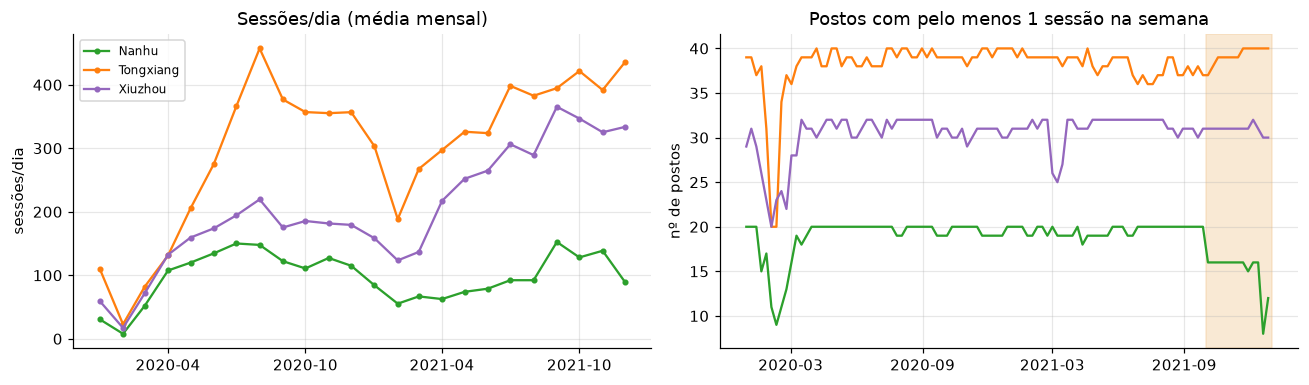

primeiro              ultimo  sessoes
district post                                                 
Nanhu    19   2020-01-01 12:52:10 2021-09-28 19:16:27     6935
         17   2020-01-01 15:27:51 2021-09-28 20:08:03     7328
         18   2020-01-01 12:14:43 2021-09-28 20:30:53     7426
         20   2020-01-01 11:59:54 2021-09-28 20:51:02     7178
Xiuzhou  80   2020-01-02 15:40:37 2021-12-06 15:21:20     3024
Nanhu    1    2020-01-01 01:42:01 2021-12-13 10:54:57     4152
         3    2020-01-03 13:09:48 2021-12-13 10:59:45     3668
         5    2020-01-01 01:45:07 2021-12-13 11:05:31     3699
         6    2020-01-01 15:40:58 2021-12-13 12:23:47     2989
Xiuzhou  76   2020-01-01 16:41:34 2021-12-19 13:11:38     4136

Nanhu, último registo em 2021-09-28: postos [19, 17, 18, 20] = 40% das sessões de Nanhu no período completo
Nanhu, último registo em 2021-12-13: postos [1, 3, 5, 6] = 20% das sessões de Nanhu no período completo
O comportamento da procura depois destas datas cai no período de teste e não é analisado aqui.


In [7]:
active = in_scope.groupby([pd.Grouper(key="start", freq="W-MON", label="left", closed="left"), "district"])["post"].nunique().unstack()
monthly_mean = daily.resample("MS").mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for lv in DISTRICTS:
    ax[0].plot(monthly_mean.index, monthly_mean[lv], marker="o", ms=3, color=COLORS[lv], label=lv)
    ax[1].plot(active.index, active[lv], color=COLORS[lv], label=lv)
ax[0].set(title="Sessões/dia (média mensal)", ylabel="sessões/dia")
ax[1].set(title="Postos com pelo menos 1 sessão na semana", ylabel="nº de postos")
ax[1].axvspan(TEST_START, SERIES_END, color="#F2C894", alpha=0.4)
ax[0].legend(fontsize=8)
for a_ in ax:
    a_.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    a_.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

post_span = in_scope.groupby(["district", "post"])["start"].agg(primeiro="min", ultimo="max", sessoes="size")
ended = post_span[post_span["ultimo"] < SERIES_END.normalize() - pd.Timedelta(days=7)].sort_values("ultimo")
display(ended)
nanhu_total = int(post_span.loc["Nanhu", "sessoes"].sum())
nanhu_ended = ended.loc["Nanhu"]
for d, g in nanhu_ended.groupby(nanhu_ended["ultimo"].dt.date):
    print(f"Nanhu, último registo em {d}: postos {list(g.index)} = {g['sessoes'].sum() / nanhu_total:.0%} das sessões de Nanhu no período completo")
print("O comportamento da procura depois destas datas cai no período de teste e não é analisado aqui.")

**Leitura.** O número de postos de Tongxiang e Xiuzhou é estável (40 e 32). Em **Nanhu há duas quebras de capacidade**, ambas a afetar o teste:

1. **2021-09-28:** os postos 17-20 deixam de registar sessões (40% das sessões de Nanhu no período completo), todos na mesma tarde.
2. **2021-12-13:** os postos 1, 3, 5 e 6 deixam de registar (20% das sessões), todos na mesma manhã. A partir daqui só restam 12 dos 20 postos.

Os postos 80 e 76 de Xiuzhou também terminam (6 e 19 de dezembro), com impacto pequeno. Os dados não permitem distinguir desativação, avaria ou perda de registos.

**Implicação.** São mudanças de regime que um modelo baseado só no histórico apenas acompanha com atraso. O teste completo mantém-se como resultado principal (representa a operação real), mas fixa-se desde já uma **análise de sensibilidade** sem os 14 dias seguintes a cada quebra (secção 5.4). O número de postos com sessões na semana anterior é um indicador de capacidade utilizável como preditor desfasado, com a ressalva de que também cai quando a procura é muito baixa (colapso de 2020, Festival da Primavera de 2021).

### 3.2 Sazonalidade

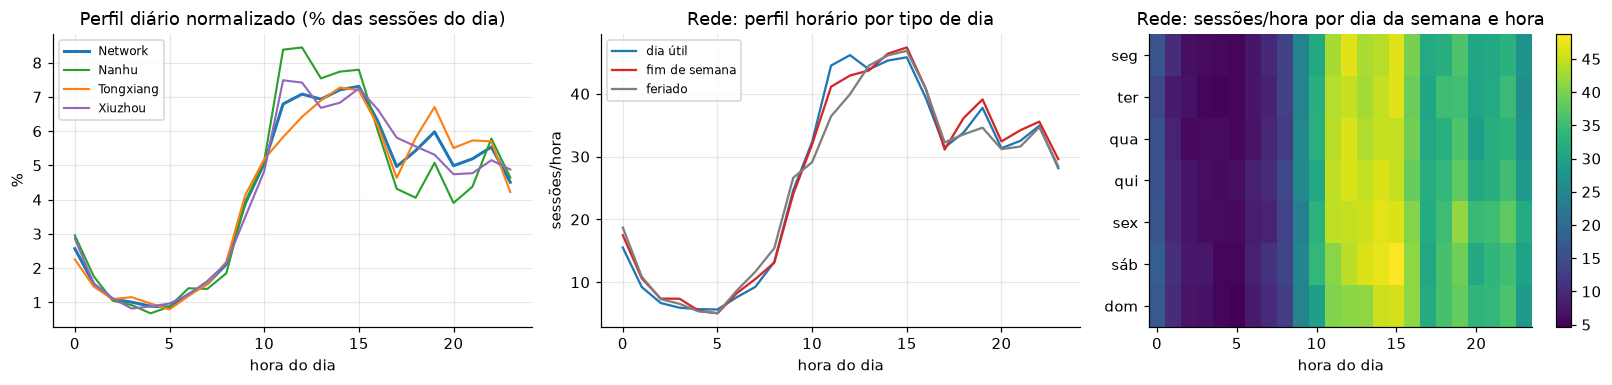

Hora de pico (média): {'Network': 15, 'Nanhu': 12, 'Tongxiang': 14, 'Xiuzhou': 11}
% das sessões entre 00h e 05h: {'Network': 7.9, 'Nanhu': 8.2, 'Tongxiang': 7.7, 'Xiuzhou': 8.2}


In [8]:
reg = hourly.loc[REGULAR_FROM:DEV_END]
reg_days = reg.index.normalize()
is_hol_h = reg_days.isin(HOLIDAY_DAYS)
is_wkend_h = (reg.index.dayofweek >= 5) & ~is_hol_h
day_type_h = np.where(is_hol_h, "feriado", np.where(is_wkend_h, "fim de semana", "dia útil"))

profile = pd.DataFrame({lv: reg[lv].groupby(reg.index.hour).mean() for lv in LEVELS})
profile_share = profile / profile.sum() * 100

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for lv in LEVELS:
    ax[0].plot(profile_share.index, profile_share[lv], color=COLORS[lv], lw=2 if lv == "Network" else 1.4, label=lv)
ax[0].set(title="Perfil diário normalizado (% das sessões do dia)", xlabel="hora do dia", ylabel="%")
ax[0].legend(fontsize=8)

net_prof = reg["Network"].groupby([day_type_h, reg.index.hour]).mean().unstack(0)
for col, c in zip(["dia útil", "fim de semana", "feriado"], ["#1F77B4", "#D62728", "#7F7F7F"]):
    ax[1].plot(net_prof.index, net_prof[col], color=c, label=col)
ax[1].set(title="Rede: perfil horário por tipo de dia", xlabel="hora do dia", ylabel="sessões/hora")
ax[1].legend(fontsize=8)

heat = reg["Network"].groupby([reg.index.dayofweek, reg.index.hour]).mean().unstack(1)
im = ax[2].imshow(heat.values, aspect="auto", cmap="viridis")
ax[2].set(title="Rede: sessões/hora por dia da semana e hora", xlabel="hora do dia")
ax[2].set_yticks(range(7), ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"])
ax[2].grid(False)
plt.colorbar(im, ax=ax[2])
plt.tight_layout()
plt.show()

peak_hour = profile.idxmax()
night_share = profile_share.loc[0:5].sum()
print("Hora de pico (média):", peak_hour.to_dict())
print("% das sessões entre 00h e 05h:", night_share.round(1).to_dict())

**Leitura.** O perfil diário é muito marcado: mínimo entre as 03h e as 06h, subida abrupta a partir das 08h e pico por volta das 11h-15h (hora de pico média da rede: 15h). Há um segundo máximo ao início da noite (19h), mais visível em Tongxiang. Nanhu e Xiuzhou concentram-se mais cedo (picos às 12h e 11h) e Tongxiang mais tarde (14h). A forma do perfil é quase igual em dias úteis, fins de semana e feriados; por isso a **hora do dia é o preditor dominante** e o tipo de dia só ajusta o nível.

,Network,Nanhu,Tongxiang,Xiuzhou
lag 1 h,0.819,0.578,0.762,0.670
lag 2 h,0.693,0.423,0.649,0.552
lag 12 h,-0.410,-0.111,-0.366,-0.226
lag 24 h,0.845,0.589,0.786,0.659
lag 48 h,0.831,0.595,0.769,0.646
lag 168 h,0.805,0.570,0.736,0.627
lag 336 h,0.776,0.551,0.711,0.593


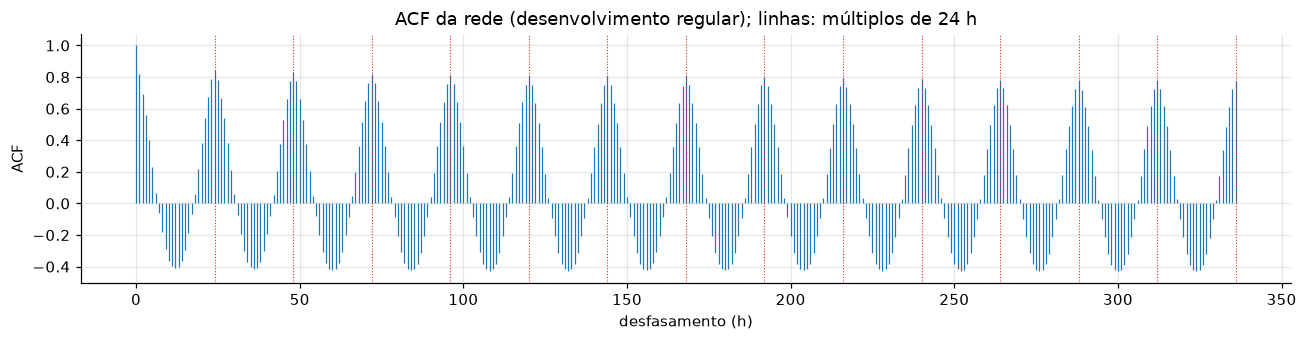

In [9]:
acfs = {lv: acf(reg[lv].astype(float), nlags=24 * 14, fft=True) for lv in LEVELS}
lag_pick = [1, 2, 12, 24, 48, 168, 336]
acf_tbl = pd.DataFrame({lv: [acfs[lv][l] for l in lag_pick] for lv in LEVELS}, index=[f"lag {l} h" for l in lag_pick])
display(acf_tbl.round(3))

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.vlines(range(len(acfs["Network"])), 0, acfs["Network"], color="#1F77B4", lw=0.8)
for k in range(1, 15):
    ax.axvline(24 * k, color="#D62728", ls=":", lw=0.7)
ax.set(title="ACF da rede (desenvolvimento regular); linhas: múltiplos de 24 h", xlabel="desfasamento (h)", ylabel="ACF")
plt.tight_layout()
plt.show()

**Leitura.** A ACF oscila com período de 24 h: máximos em múltiplos de 24 h (0,85 em 24 h, 0,83 em 48 h, 0,81 em 168 h) e mínimos negativos perto de 12 h (-0,41). A correlação em 168 h é só ligeiramente inferior à de 24 h, pelo que o ciclo semanal acrescenta pouco. Em Nanhu as correlações são bem mais baixas (0,58 em 1 h e 0,59 em 24 h), porque as contagens são pequenas e ruidosas.

**Implicação:** a diferenciação sazonal natural é a de 24 h ($m=24$), e os *lags* 24, 48, 168 e 336 h são candidatos a preditores (utilizáveis em todos os horizontes de 1 a 24 h).

,força sazonal 24 h,força sazonal 168 h,força da tendência
nível,,,
Network,0.875,0.179,0.548
Nanhu,0.681,0.182,0.274
Tongxiang,0.819,0.164,0.489
Xiuzhou,0.718,0.182,0.399


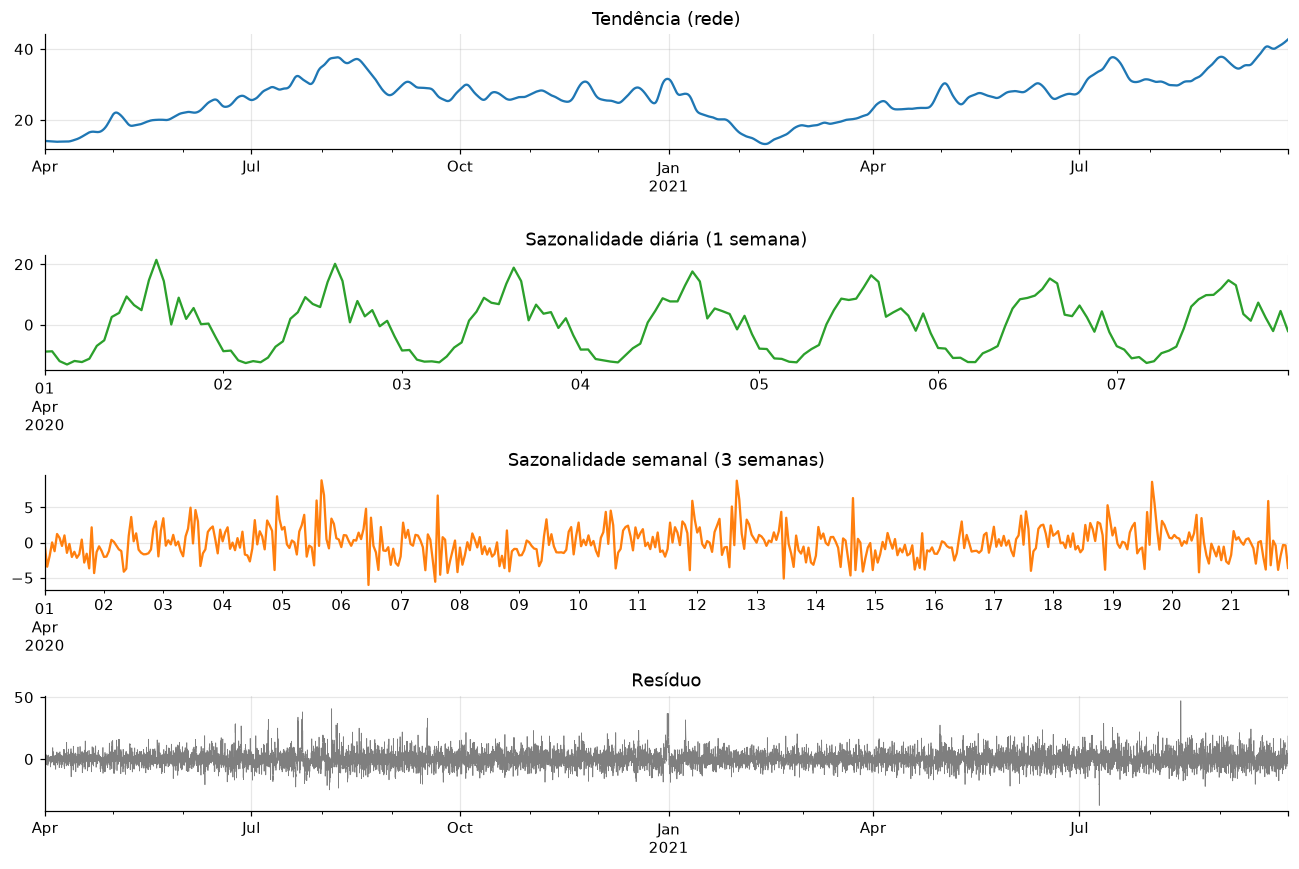

In [10]:
def strength(component, resid):
    return float(max(0.0, 1 - resid.var() / (component + resid).var()))

mstl = {}
rows = []
for lv in LEVELS:
    res = MSTL(reg[lv].astype(float), periods=[24, 168]).fit()
    mstl[lv] = res
    rows.append({
        "nível": lv,
        "força sazonal 24 h": strength(res.seasonal["seasonal_24"], res.resid),
        "força sazonal 168 h": strength(res.seasonal["seasonal_168"], res.resid),
        "força da tendência": strength(res.trend, res.resid),
    })
strength_tbl = pd.DataFrame(rows).set_index("nível")
display(strength_tbl.round(3))

res = mstl["Network"]
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=False)
res.trend.plot(ax=axes[0], color="#1F77B4"); axes[0].set_title("Tendência (rede)")
w1 = res.seasonal["seasonal_24"].iloc[:24 * 7]; w1.plot(ax=axes[1], color="#2CA02C"); axes[1].set_title("Sazonalidade diária (1 semana)")
w2 = res.seasonal["seasonal_168"].iloc[:24 * 21]; w2.plot(ax=axes[2], color="#FF7F0E"); axes[2].set_title("Sazonalidade semanal (3 semanas)")
res.resid.plot(ax=axes[3], color="#7F7F7F", lw=0.5); axes[3].set_title("Resíduo")
for a in axes:
    a.set_xlabel("")
plt.tight_layout()
plt.show()

**Leitura.** A decomposição MSTL (24 h e 168 h) confirma a leitura da ACF:

| nível | força sazonal 24 h | força sazonal 168 h | força da tendência |
|---|---|---|---|
| Rede | 0,88 | 0,18 | 0,55 |
| Nanhu | 0,68 | 0,18 | 0,27 |
| Tongxiang | 0,82 | 0,16 | 0,49 |
| Xiuzhou | 0,72 | 0,18 | 0,40 |

A sazonalidade diária é forte em todos os níveis e a semanal é fraca; a componente semanal do gráfico tem amplitude pequena face ao resíduo. A tendência pesa moderadamente e menos em Nanhu. O resíduo é maior quando a procura é mais alta (variância não constante), típico de contagens.

In [11]:
# Resíduos extremos da rede (MAD robusto): erro de dados ou comportamento real?
resid = mstl["Network"].resid
z = (resid - resid.median()) / (1.4826 * (resid - resid.median()).abs().median())
top = pd.DataFrame({"sessões": reg["Network"], "resíduo": resid, "z robusto": z, "feriado": reg_days.isin(HOLIDAY_DAYS)})
top = top.reindex(z.abs().sort_values(ascending=False).index).head(10)
display(top.round(2))
print(f"Horas com |z| > 5: {int((z.abs() > 5).sum())} de {len(z):,} ({(z.abs() > 5).mean():.2%})")

,sessões,resíduo,z robusto,feriado
hour,,,,
2021-08-14 17:00:00,96,47.140,10.680,False
2020-08-05 11:00:00,129,40.680,9.230,False
2020-07-23 14:00:00,108,38.130,8.650,False
2021-07-09 19:00:00,8,-37.520,-8.380,False
2020-12-31 09:00:00,81,36.880,8.370,False
2020-12-31 19:00:00,83,36.870,8.370,False
2020-12-31 14:00:00,94,33.960,7.710,False
2020-07-21 15:00:00,95,33.830,7.680,False
2020-09-16 16:00:00,88,32.990,7.490,False


Horas com |z| > 5: 52 de 13,152 (0.40%)


**Leitura.** Só 52 de 13 152 horas (0,4%) têm resíduo robusto acima de 5 desvios, e as maiores não parecem erros de dados:

- **2020-12-31** (véspera do feriado de Ano Novo): 1 219 sessões no dia, cerca do dobro do habitual, com resíduos de +37 sessões/hora. É um efeito de **véspera de feriado**, que justifica essa variável de calendário.
- Picos em dias de verão de 2020 e em 2021-08-14 (dia de chuva forte, 21 a 23 mm).
- O mínimo (2021-07-09, 19h: 8 sessões contra ~45 esperadas) ocorre nos três distritos ao mesmo tempo, o que aponta para um evento comum (por exemplo, indisponibilidade do serviço); a causa não é verificável nos dados.

Mantêm-se todos: remover picos tornaria os modelos piores nos dias de maior procura.

In [12]:
# Efeito de calendário: procura diária relativa à mediana móvel centrada de 29 dias.
trend_d = dev_daily.rolling(29, center=True, min_periods=15).median()
ratio_d = (dev_daily / trend_d).loc[REGULAR_FROM:]
dt_d = pd.Series(
    np.where(ratio_d.index.isin(HOLIDAY_DAYS), "feriado",
             np.where(ratio_d.index.dayofweek >= 5, "fim de semana", "dia útil")),
    index=ratio_d.index,
)
daytype_tbl = ratio_d.groupby(dt_d).median().T[["dia útil", "fim de semana", "feriado"]]
daytype_tbl.loc["(nº de dias)"] = dt_d.value_counts()[["dia útil", "fim de semana", "feriado"]].to_numpy()
display(daytype_tbl.round(3))

dow_tbl = ratio_d.groupby(ratio_d.index.dayofweek).median()
dow_tbl.index = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
display(dow_tbl.T.round(3))

hol = ratio_d[ratio_d.index.isin(HOLIDAY_DAYS)]["Network"]
hol_by_block = pd.Series(
    {name + " " + a[:4]: ratio_d.loc[a:b, "Network"].median() for a, b, name in HOLIDAY_RANGES if pd.Timestamp(a) >= REGULAR_FROM and pd.Timestamp(b) <= DEV_END}
)
display(hol_by_block.round(3).to_frame("mediana relativa (rede)"))

,dia útil,fim de semana,feriado
district,,,
Network,0.996,1.008,1.118
Nanhu,1.000,1.000,1.052
Tongxiang,0.990,1.013,1.105
Xiuzhou,0.985,1.017,1.145
(nº de dias),367.000,138.000,43.000


,seg,ter,qua,qui,sex,sáb,dom
district,,,,,,,
Network,0.987,0.994,0.991,0.992,1.020,1.044,1.002
Nanhu,0.997,0.980,1.000,1.000,1.053,1.015,0.994
Tongxiang,0.978,0.985,0.991,0.995,1.017,1.050,1.000
Xiuzhou,0.984,0.982,0.978,1.000,1.018,1.045,1.017


,mediana relativa (rede)
Qingming 2020,1.045
Dia do Trabalhador 2020,1.182
Dragon Boat 2020,1.173
Dia Nacional + Meio-Outono 2020,1.109
Ano Novo 2021,1.116
Festival da Primavera 2021,0.861
Qingming 2021,1.229
Dia do Trabalhador 2021,1.237
Dragon Boat 2021,1.114
Meio-Outono 2021,1.082


**Leitura.** O efeito do calendário é pequeno, exceto nos feriados:

- Fim de semana vs dia útil: razão de cerca de 1,01 na rede (sábado 1,04; sexta 1,02).
- **Feriados:** +12% na rede (Xiuzhou +15%, Tongxiang +11%, Nanhu +5%). O efeito não é homogéneo: Dia do Trabalhador (+18% e +24%), Qingming 2021 (+23%) e Dragon Boat (+11% a +17%) contrastam com o **Festival da Primavera de 2021, que reduz a procura em 14%**.

**Implicação:** o feriado entra como variável de calendário, mas **um único indicador binário mistura efeitos de sinal oposto**; convém separar o Festival da Primavera e marcar véspera e dia seguinte. O calendário foi inserido manualmente e deve ser validado contra a fonte oficial antes de modelar.

### 3.3 Distribuição e natureza de contagem

In [13]:
rows = {}
for lv in LEVELS:
    s = reg[lv]
    cells = s.groupby([s.index.to_period("M"), s.index.hour]).agg(["mean", "var"])
    cells = cells[(cells["mean"] > 0) & (cells["var"] > 0)]
    slope = np.polyfit(np.log(cells["mean"]), np.log(cells["var"]), 1)[0]
    rows[lv] = {
        "média (sessões/h)": s.mean(), "desvio-padrão": s.std(), "variância/média": s.var() / s.mean(),
        "% horas a zero": (s == 0).mean() * 100, "p95": s.quantile(0.95), "máximo": s.max(),
        "expoente variância~média^k": slope,
    }
desc_tbl = pd.DataFrame(rows).T
display(desc_tbl.round(2))

,média (sessões/h),desvio-padrão,variância/média,% horas a zero,p95,máximo,expoente variância~média^k
Network,26.380,17.850,12.080,0.400,58.000,129.000,1.150
Nanhu,4.390,4.160,3.950,14.990,12.000,47.000,1.130
Tongxiang,13.380,9.620,6.920,2.100,30.000,73.000,1.130
Xiuzhou,8.610,7.210,6.030,6.520,22.000,63.000,1.090


**Leitura.** A variância é muito superior à média (razão de 12 na rede e de 4 a 7 nos distritos): há **sobredispersão**, e as contagens horárias não seguem um Poisson simples. A variância cresce quase linearmente com a média (expoente cerca de 1,1). Nanhu tem 15% de horas a zero no período regular, o que inviabiliza erros percentuais (MAPE) e justifica MAE/RMSE/MASE. Modelos com erros gaussianos são uma aproximação razoável na rede e menos em Nanhu.

### 3.4 Diferenças entre distritos

In [14]:
rows = {}
for lv in DISTRICTS:
    s = reg[lv]
    n_posts = post_span.loc[lv].shape[0]
    rows[lv] = {
        "postos": n_posts,
        "sessões/dia (média)": dev_daily.loc[REGULAR_FROM:, lv].mean(),
        "% da rede": reg[lv].sum() / reg["Network"].sum() * 100,
        "sessões/posto/dia": dev_daily.loc[REGULAR_FROM:, lv].mean() / n_posts,
        "hora de pico": int(peak_hour[lv]),
        "% sessões 00h-05h": night_share[lv],
        "fim de semana / dia útil": ratio_d[lv][dt_d.eq("fim de semana")].median() / ratio_d[lv][dt_d.eq("dia útil")].median(),
        "feriado / dia útil": ratio_d[lv][dt_d.eq("feriado")].median() / ratio_d[lv][dt_d.eq("dia útil")].median(),
        "% horas a zero": (s == 0).mean() * 100,
    }
district_cmp = pd.DataFrame(rows)
display(district_cmp.round(2))

corr_ratio = ratio_d[DISTRICTS].corr(method="spearman")
print("Correlação (Spearman) da procura diária relativa à tendência entre distritos:")
display(corr_ratio.round(2))

,Nanhu,Tongxiang,Xiuzhou
postos,20.000,40.000,32.000
sessões/dia (média),105.400,321.060,206.710
% da rede,16.650,50.710,32.650
sessões/posto/dia,5.270,8.030,6.460
hora de pico,12.000,14.000,11.000
% sessões 00h-05h,8.230,7.710,8.180
fim de semana / dia útil,1.000,1.020,1.030
feriado / dia útil,1.050,1.120,1.160
% horas a zero,14.990,2.100,6.520


Correlação (Spearman) da procura diária relativa à tendência entre distritos:


district,Nanhu,Tongxiang,Xiuzhou
district,,,
Nanhu,1.000,0.300,0.260
Tongxiang,0.300,1.000,0.410
Xiuzhou,0.260,0.410,1.000


**Leitura.** Tongxiang tem metade da rede (51%), Xiuzhou um terço (33%) e Nanhu 17%. A intensidade por posto difere (8,0, 6,5 e 5,3 sessões/posto/dia). Depois de removida a tendência, a procura dos distritos está **fracamente correlacionada** (Spearman 0,26 a 0,41), logo a previsão por distrito não é redundante com a da rede. Se a rede for obtida como soma dos distritos, é preciso verificar a coerência.

### 3.5 Meteorologia: granularidade, alinhamento e sinal

In [15]:
dd = in_scope.assign(date=in_scope["start"].dt.floor("D"))
granularity = dd.groupby(["district", "date"])[["temp", "rh", "prec"]].nunique().max()
print("Valores distintos de cada variável por (distrito, dia) — máximo:", granularity.to_dict())

weather_daily = (
    dd.groupby(["district", "date"])[["temp", "rh", "prec"]].first().reset_index()
)
weather_daily["known_at"] = weather_daily["date"] + pd.Timedelta(days=1)
print("Dias com meteorologia por distrito:", weather_daily.groupby("district").size().to_dict())

rows = {}
for lv in DISTRICTS:
    w = weather_daily[weather_daily["district"] == lv].set_index("date")[["temp", "rh", "prec"]]
    w = w.reindex(ratio_d.index)
    r = ratio_d[lv]
    rows[lv] = {
        "temp (dia D)": r.corr(w["temp"], method="spearman"),
        "temp (D-1)": r.corr(w["temp"].shift(1), method="spearman"),
        "humidade (dia D)": r.corr(w["rh"], method="spearman"),
        "humidade (D-1)": r.corr(w["rh"].shift(1), method="spearman"),
        "precipitação (dia D)": r.corr(w["prec"], method="spearman"),
        "precipitação (D-1)": r.corr(w["prec"].shift(1), method="spearman"),
    }
weather_corr = pd.DataFrame(rows).T
display(weather_corr.round(3))

Valores distintos de cada variável por (distrito, dia) — máximo: {'temp': 1, 'rh': 1, 'prec': 1}
Dias com meteorologia por distrito: {'Nanhu': 730, 'Tongxiang': 731, 'Xiuzhou': 731}


,temp (dia D),temp (D-1),humidade (dia D),humidade (D-1),precipitação (dia D),precipitação (D-1)
Nanhu,0.047,0.033,-0.086,-0.065,-0.041,0.062
Tongxiang,0.102,0.078,-0.152,-0.034,-0.059,0.005
Xiuzhou,0.040,0.034,-0.100,-0.022,-0.081,0.018


**Leitura.** O ficheiro tem **um único valor por distrito e dia** (temperatura, humidade e precipitação), e não uma série horária. Não explica a variação intradiária e só é utilizável com atraso de pelo menos um dia (secção 4.3). A relação com a procura diária relativa à tendência é fraca (|ρ| ≤ 0,16): humidade do dia entre -0,09 e -0,15, temperatura até 0,10, precipitação entre -0,04 e -0,08. Nanhu e Xiuzhou têm valores praticamente iguais, o que reduz a informação distintiva.

**Implicação:** espera-se pouco ganho da meteorologia. Testa-se em validação, sempre desfasada; a versão do próprio dia serve apenas como oráculo diagnóstico.

### 3.6 Estacionariedade

In [16]:
def stationarity(x):
    x = pd.Series(x).dropna().astype(float)
    return adfuller(x, maxlag=48, autolag="AIC")[1], kpss(x, regression="c", nlags="auto")[1]

rows = []
for lv in LEVELS:
    h = reg[lv]
    d = dev_daily.loc[REGULAR_FROM:, lv]
    for label, x in [
        ("horária (nível)", h), ("horária, dif. 24 h", h.diff(24)),
        ("diária (nível)", d), ("diária, dif. 7 d", d.diff(7)),
    ]:
        adf_p, kpss_p = stationarity(x)
        rows.append({"nível": lv, "série": label, "p-valor ADF": adf_p, "p-valor KPSS": kpss_p,
                     "leitura": "estacionária" if (adf_p < 0.05 and kpss_p >= 0.05) else "não conclusiva / não estacionária"})
stat_tbl = pd.DataFrame(rows).set_index(["nível", "série"])
display(stat_tbl.round(4))
print("Os p-valores do KPSS vêm truncados a [0.01, 0.10]. Leitura: estacionária se ADF < 0.05 e KPSS >= 0.05.")

p-valor ADF  p-valor KPSS                            leitura
nível     série                                                                           
Network   horária (nível)           0.011         0.010  não conclusiva / não estacionária
          horária, dif. 24 h        0.000         0.100                       estacionária
          diária (nível)            0.335         0.012  não conclusiva / não estacionária
          diária, dif. 7 d          0.044         0.100                       estacionária
Nanhu     horária (nível)           0.000         0.010  não conclusiva / não estacionária
          horária, dif. 24 h        0.000         0.100                       estacionária
          diária (nível)            0.785         0.010  não conclusiva / não estacionária
          diária, dif. 7 d          0.154         0.100  não conclusiva / não estacionária
Tongxiang horária (nível)           0.001         0.010  não conclusiva / não estacionária
          horária, dif. 24 h        0.000         0.100                       estacionária
          diária (nível)            0.085         0.031  não conclusiva / não estacionária
          diária, dif. 7 d          0.015         0.100                       estacionária
Xiuzhou   horária (nível)           0.007         0.010  não conclusiva / não estacionária
          horária, dif. 24 h        0.000         0.100                       estacionária
          diária (nível)            0.750         0.010  não conclusiva / não estacionária
          diária, dif. 7 d          0.002         0.100                       estacionária

Os p-valores do KPSS vêm truncados a [0.01, 0.10]. Leitura: estacionária se ADF < 0.05 e KPSS >= 0.05.


**Leitura.** Nas séries em nível, ADF e KPSS divergem: o ADF rejeita a raiz unitária na série horária, mas o KPSS rejeita a estacionariedade (p = 0,01). A leitura conjunta é "não conclusiva / não estacionária", coerente com a tendência e a sazonalidade. Com **diferenciação sazonal de 24 h** as quatro séries horárias passam a estacionárias (ADF p ≈ 0, KPSS p ≥ 0,10). No nível diário, a diferença de 7 dias resolve a rede, Tongxiang e Xiuzhou, mas não Nanhu (ADF p = 0,15), que tem quebras de capacidade.

**Implicação para a Task 2:** ponto de partida $D=1$ com $m=24$ nos modelos SARIMA.

## 4. Formulação operacional da previsão

### 4.1 Calendário de emissão

- **Emissão diária às 00:00 (hora local).** No instante $T_0$ (00:00 do dia $D$) está disponível todo o histórico até à hora que termina em $T_0$ (a hora iniciada a $T_0-1\,\text{h}$).
- **Horizonte $h = 1,\dots,24$:** número de sessões iniciadas em $[T_0+h-1,\; T_0+h)$, ou seja, as 24 horas do dia $D$.

**Porquê esta escolha.** (i) É um verdadeiro *day-ahead*: uma previsão por dia, útil para planear capacidade e tarifas do dia seguinte. (ii) Alinha-se com o ciclo diário dominante: cada horizonte corresponde a uma hora do dia fixa, o que facilita comparar horizontes. (iii) As origens não se sobrepõem (731 origens possíveis), o que mantém o custo de avaliação compatível com modelos estatísticos reestimados por *fold*.

**Limitação assumida.** Com emissão às 00:00, o horizonte $h$ coincide com a hora do dia $h-1$, pelo que o erro por horizonte mistura "distância temporal" com "nível da procura" (as horas noturnas têm menos sessões). Por isso a comparação entre horizontes usa o **MASE**, que normaliza pela escala da série. Outros horários de emissão obtêm-se deslocando a origem, sem alterar o protocolo.

In [17]:
origin = pd.Timestamp("2021-03-10 00:00")
fmt = lambda t: t.strftime("%m-%d %H:%M")
mapping = pd.DataFrame({
    "intervalo alvo": [f"[{fmt(origin + pd.Timedelta(hours=int(h) - 1))}, {fmt(origin + pd.Timedelta(hours=int(h)))})" for h in HORIZONS],
    "hora do dia": HORIZONS - 1,
}, index=pd.Index(HORIZONS, name="horizonte h"))
print(f"Exemplo: emissão em {origin} | último dado usado: hora iniciada em {origin - pd.Timedelta(hours=1)} (termina às {origin:%H:%M})")
display(mapping.loc[[1, 2, 12, 24]])

Exemplo: emissão em 2021-03-10 00:00:00 | último dado usado: hora iniciada em 2021-03-09 23:00:00 (termina às 00:00)


,intervalo alvo,hora do dia
horizonte h,,
1,"[03-10 00:00, 03-10 01:00)",0
2,"[03-10 01:00, 03-10 02:00)",1
12,"[03-10 11:00, 03-10 12:00)",11
24,"[03-10 23:00, 03-11 00:00)",23


### 4.2 Estratégia multi-passo

| Família de modelos | Estratégia | Justificação |
|---|---|---|
| Estatísticos (Task 2: ETS, ARIMA/SARIMA, SARIMAX) | **Iterada (recursiva)**: um ajuste por *fold*; em cada origem, previsão de 24 passos a partir do estado atualizado com os valores observados até $T_0$, **sem reestimar parâmetros todos os dias** | É a forma natural destes modelos; reestimar diariamente seria desnecessariamente caro |
| Aprendizagem automática (tarefas seguintes) | **Direta**: um modelo por horizonte, ou um único modelo com $h$ como atributo | Evita acumulação de erros e permite alinhar os preditores com cada horizonte |
| Níveis geográficos | Previsão **independente** em cada nível (rede e 3 distritos), com verificação posterior da coerência (soma dos distritos vs. rede); reconciliação *bottom-up* como alternativa | A rede é a soma dos distritos por construção (verificado na secção 2) |

Todos os modelos são comparados nas **mesmas origens** e com as **mesmas métricas**.

### 4.3 Informação disponível no instante de emissão

In [18]:
policy = pd.DataFrame([
    ("Histórico da procura (alvo)", "lags 24, 48, 168, 336 h; média da mesma hora nos últimos 7 dias e da mesma hora da semana nas últimas 4 semanas; média das últimas 24 h e 7 dias; razão entre 7 dias recentes e os 7 anteriores",
     "Observado até T0 − 1 h", "Lag L só é utilizável no horizonte h se L >= h", "Usar"),
    ("Histórico agregado / hierárquico", "procura dos outros distritos e da rede (mesmas regras); nº de postos com sessões nos últimos 7 dias (proxy de capacidade)",
     "Observado até T0 − 1 h", "Mesma regra de lags", "Usar"),
    ("Calendário determinístico (futuro conhecido)", "hora do dia, dia da semana, fim de semana, feriado oficial, véspera e dia seguinte a feriado, posição no bloco de feriados",
     "Conhecido para qualquer data futura", "Sem restrição temporal", "Usar"),
    ("Tendência e anual", "índice temporal linear; mês / dia do ano",
     "Determinístico", "Extrapolação / só 2 anos, um deles afetado pela COVID-19", "Não usar como preditor principal; só como sensibilidade"),
    ("Meteorologia do dia D", "temperatura, humidade, precipitação (valor único por distrito e dia)",
     "Não disponível em T0 (resumo diário só conhecido em D+1 00:00)", "known_at = D+1 00:00", "Excluir; só análise diagnóstica ('oráculo'), nunca para seleção"),
    ("Meteorologia até D − 1", "as mesmas variáveis, desfasadas >= 1 dia",
     "Conhecida em T0 (known_at <= T0)", "Junção por known_at <= origem", "Admissível como regressor desfasado, se acrescentar valor nos folds"),
    ("Previsões meteorológicas", "—", "Não existem no conjunto de dados", "Só seriam válidas se arquivadas e emitidas antes de T0", "Não usar"),
    ("Variáveis da transação", "energia, custo, duração, fim e pagamento",
     "Só conhecidas depois da sessão", "—", "Excluir (leakage)"),
], columns=["grupo", "variáveis", "disponibilidade em T0", "regra de alinhamento", "decisão"])
pd.set_option("display.max_colwidth", 120)
display(policy)

,grupo,variáveis,disponibilidade em T0,regra de alinhamento,decisão
0,Histórico da procura (alvo),"lags 24, 48, 168, 336 h; média da mesma hora nos últimos 7 dias e da mesma hora da semana nas últimas 4 semanas; méd...",Observado até T0 − 1 h,Lag L só é utilizável no horizonte h se L >= h,Usar
1,Histórico agregado / hierárquico,procura dos outros distritos e da rede (mesmas regras); nº de postos com sessões nos últimos 7 dias (proxy de capaci...,Observado até T0 − 1 h,Mesma regra de lags,Usar
2,Calendário determinístico (futuro conhecido),"hora do dia, dia da semana, fim de semana, feriado oficial, véspera e dia seguinte a feriado, posição no bloco de fe...",Conhecido para qualquer data futura,Sem restrição temporal,Usar
3,Tendência e anual,índice temporal linear; mês / dia do ano,Determinístico,"Extrapolação / só 2 anos, um deles afetado pela COVID-19",Não usar como preditor principal; só como sensibilidade
4,Meteorologia do dia D,"temperatura, humidade, precipitação (valor único por distrito e dia)",Não disponível em T0 (resumo diário só conhecido em D+1 00:00),known_at = D+1 00:00,"Excluir; só análise diagnóstica ('oráculo'), nunca para seleção"
5,Meteorologia até D − 1,"as mesmas variáveis, desfasadas >= 1 dia",Conhecida em T0 (known_at <= T0),Junção por known_at <= origem,"Admissível como regressor desfasado, se acrescentar valor nos folds"
6,Previsões meteorológicas,—,Não existem no conjunto de dados,Só seriam válidas se arquivadas e emitidas antes de T0,Não usar
7,Variáveis da transação,"energia, custo, duração, fim e pagamento",Só conhecidas depois da sessão,—,Excluir (leakage)


In [19]:
# 1) Regra dos lags: o alvo de horizonte h está em T0 + h - 1; um lag L só é conhecido se L >= h.
LAGS = [1, 2, 3, 6, 12, 24, 48, 168, 336]
lag_ok = pd.DataFrame(
    {f"h={h}": ["sim" if l >= h else "não" for l in LAGS] for h in [1, 6, 12, 18, 24]},
    index=[f"lag {l} h" for l in LAGS],
)
display(lag_ok)

# 2) Meteorologia: em cada origem só podem existir valores com known_at <= origem (até D-1).
checked = 0
for o in pd.date_range("2020-02-01", DEV_END.normalize(), freq="23D"):
    avail = weather_daily[weather_daily["known_at"] <= o]
    assert (avail["known_at"] <= o).all()
    assert avail["date"].max() == o - pd.Timedelta(days=1)
    assert weather_daily[(weather_daily["date"] == o)]["known_at"].gt(o).all()
    checked += 1
print(f"Meteorologia: em {checked} origens, só há dados até D-1; o dia D nunca está disponível.")

,h=1,h=6,h=12,h=18,h=24
lag 1 h,sim,não,não,não,não
lag 2 h,sim,não,não,não,não
lag 3 h,sim,não,não,não,não
lag 6 h,sim,sim,não,não,não
lag 12 h,sim,sim,sim,não,não
lag 24 h,sim,sim,sim,sim,sim
lag 48 h,sim,sim,sim,sim,sim
lag 168 h,sim,sim,sim,sim,sim
lag 336 h,sim,sim,sim,sim,sim


Meteorologia: em 27 origens, só há dados até D-1; o dia D nunca está disponível.


**Leitura.** Em 27 origens verificadas, a meteorologia do dia D nunca está disponível (só até D-1), pelo que é a fonte mais provável de *leakage*. Pela regra $L \geq h$, à meia-noite só os *lags* de 24 h ou mais servem em todos os horizontes; os *lags* de 1 a 12 h só servem nos horizontes curtos. As variáveis da transação (energia, duração, custo, fim) só são conhecidas depois da sessão e ficam excluídas.

## 5. Protocolo de avaliação

### 5.1 Partição cronológica

- **Teste final independente:** 2021-10-01 a 2021-12-31 (último trimestre, 92 dias, 2 208 horas por nível). Fica protegido até à seleção final do modelo.
- **Desenvolvimento:** 2020-01-01 a 2021-09-30, com **validação em janela expansiva** e 4 *folds* trimestrais (T4 2020, T1, T2 e T3 2021). Em cada *fold* o treino termina na véspera do bloco de validação.
- **Sem sobreposição:** as origens são diárias e o alvo de cada origem é o próprio dia; o último dia de treino termina antes do primeiro dia de validação, pelo que não é necessária purga adicional.
- **Estabilidade temporal:** resultados reportados por *fold*, com média, desvio-padrão e pior *fold*.
- **O início de 2020 (COVID-19)** só aparece nas janelas de treino. Fica como decisão da Task 2 se o treino deve ou não incluir esse regime (por exemplo, janela deslizante ou início em abril de 2020).

In [20]:
DAYS = pd.date_range(SERIES_START.normalize(), SERIES_END.normalize(), freq="D")
Y = {lv: hourly[lv].to_numpy().reshape(len(DAYS), 24) for lv in LEVELS}
day_idx = lambda d: int((pd.Timestamp(d) - DAYS[0]).days)

QUARTERS = [("2020-10-01", "2020-12-31"), ("2021-01-01", "2021-03-31"), ("2021-04-01", "2021-06-30"), ("2021-07-01", "2021-09-30")]
FOLDS = [{"name": f"F{i}", "train": (str(SERIES_START.date()), str((pd.Timestamp(a) - pd.Timedelta(days=1)).date())), "val": (a, b)}
         for i, (a, b) in enumerate(QUARTERS, 1)]
TEST = (str(TEST_START.date()), str(SERIES_END.date()))

# Contrato de origem: o histórico termina em T0 - 1 h e o primeiro alvo é T0; sem sobreposição entre blocos.
for a, b in [f["val"] for f in FOLDS] + [TEST]:
    for d in range(day_idx(a), day_idx(b) + 1):
        assert hourly.index[d * 24 - 1] == DAYS[d] - pd.Timedelta(hours=1) and hourly.index[d * 24] == DAYS[d]
ends = [pd.Timestamp(f["val"][1]) for f in FOLDS]
starts = [pd.Timestamp(f["val"][0]) for f in FOLDS]
assert all(e < s for e, s in zip(ends[:-1], starts[1:])) and ends[-1] < pd.Timestamp(TEST[0])
assert all(pd.Timestamp(f["train"][1]) < pd.Timestamp(f["val"][0]) for f in FOLDS)

split_tbl = pd.DataFrame([
    {"bloco": f["name"], "treino": f"{f['train'][0]} a {f['train'][1]}", "validação / teste": f"{f['val'][0]} a {f['val'][1]}",
     "dias de treino": day_idx(f["val"][0]), "origens": day_idx(f["val"][1]) - day_idx(f["val"][0]) + 1}
    for f in FOLDS
] + [{"bloco": "Teste", "treino": f"{FOLDS[0]['train'][0]} a {str((pd.Timestamp(TEST[0]) - pd.Timedelta(days=1)).date())} (desenvolvimento)",
      "validação / teste": f"{TEST[0]} a {TEST[1]}", "dias de treino": day_idx(TEST[0]), "origens": day_idx(TEST[1]) - day_idx(TEST[0]) + 1}]).set_index("bloco")
split_tbl["previsões horárias por nível"] = split_tbl["origens"] * 24
display(split_tbl)

# Análise de sensibilidade fixada já aqui: teste sem os 14 dias a seguir a cada quebra de capacidade.
_test_days = pd.date_range(TEST[0], TEST[1], freq="D")
SENS_DAYS = sorted({pd.Timestamp(b) + pd.Timedelta(days=k) for bs in CAPACITY_BREAKS.values() for b in bs for k in range(1, 15)} & set(_test_days))
print(f"Dias excluídos na análise de sensibilidade do teste: {len(SENS_DAYS)} de {len(_test_days)}")
print("Intervalos:", [(str(g[0].date()), str(g[-1].date())) for g in np.split(np.array(SENS_DAYS), np.where(np.diff(SENS_DAYS) > pd.Timedelta(days=1))[0] + 1)])

,treino,validação / teste,dias de treino,origens,previsões horárias por nível
bloco,,,,,
F1,2020-01-01 a 2020-09-30,2020-10-01 a 2020-12-31,274,92,2208
F2,2020-01-01 a 2020-12-31,2021-01-01 a 2021-03-31,366,90,2160
F3,2020-01-01 a 2021-03-31,2021-04-01 a 2021-06-30,456,91,2184
F4,2020-01-01 a 2021-06-30,2021-07-01 a 2021-09-30,547,92,2208
Teste,2020-01-01 a 2021-09-30 (desenvolvimento),2021-10-01 a 2021-12-31,639,92,2208


Dias excluídos na análise de sensibilidade do teste: 26 de 92
Intervalos: [('2021-10-01', '2021-10-12'), ('2021-12-14', '2021-12-27')]


**Leitura.** Quatro *folds* de validação com janela expansiva (trimestres de 2020-Q4 a 2021-Q3) e teste final em 2021-Q4, sem sobreposição e com treino sempre anterior à validação. Cada bloco tem 90 a 92 origens (2 160 a 2 208 previsões horárias por nível). As asserções confirmam, para todas as origens, que o último dado usado termina à hora anterior a $T_0$.

**Riscos do teste:** (i) as duas quebras de capacidade de Nanhu (secção 3.1); (ii) o Dia Nacional só tem um exemplo anterior (2020-Q4); (iii) com a procura em crescimento, o MASE com escala do treino pode ficar acima de 1 mesmo com boas previsões. A análise de sensibilidade (secção 5.4) trata o ponto (i).

### 5.2 Métricas

- **MAE** e **RMSE** em sessões/hora (RMSE penaliza erros grandes, relevantes para picos).
- **MASE** com escala = MAE *in-sample* do *seasonal naïve* de período $m$ na janela de treino de cada *fold* e de cada nível:

$$\text{MASE}=\frac{\text{MAE}}{\frac{1}{n-m}\sum_{t=m+1}^{n}|y_t-y_{t-m}|}$$

- **Não se usa MAPE/sMAPE:** as séries têm horas com procura zero (sobretudo em Nanhu), o que torna esses erros indefinidos ou instáveis.
- **Agregação:** por horizonte, por *fold*, por nível e global. O RMSE global é a raiz da média dos erros quadráticos (não a média de RMSEs).
- **Métricas operacionais complementares:** acerto da **hora de pico** do dia (dentro de ±1 h) e erro absoluto do **valor do pico** diário.
- **Custo computacional:** tempo de previsão por origem e, nos modelos treináveis, tempo de ajuste por *fold*.

**Período sazonal do MASE.** Escolhe-se $m=24$ por ser o ciclo dominante. A tabela mostra a escala para $m=1, 24, 168$ e a força sazonal de cada ciclo (secção 3.2).

In [21]:
scale_cmp = pd.DataFrame({
    lv: {f"MAE naïve m={m}": np.abs(reg[lv].to_numpy()[m:] - reg[lv].to_numpy()[:-m]).mean() for m in [1, 24, 168]}
    for lv in LEVELS
}).T
scale_cmp["razão m=168 / m=24"] = scale_cmp["MAE naïve m=168"] / scale_cmp["MAE naïve m=24"]
scale_cmp = scale_cmp.join(strength_tbl[["força sazonal 24 h", "força sazonal 168 h"]])
display(scale_cmp.round(3))

,MAE naïve m=1,MAE naïve m=24,MAE naïve m=168,razão m=168 / m=24,força sazonal 24 h,força sazonal 168 h
Network,8.013,7.124,7.660,1.075,0.875,0.179
Nanhu,2.652,2.529,2.549,1.008,0.681,0.182
Tongxiang,4.933,4.481,4.857,1.084,0.819,0.164
Xiuzhou,4.235,4.190,4.280,1.022,0.718,0.182


**Leitura.** Escolhe-se $m=24$: o *naïve* de 24 h tem MAE inferior ao de 168 h em todos os níveis (razão de 1,01 a 1,08) e a força sazonal diária (0,68 a 0,88) é muito superior à semanal (cerca de 0,18). A escolha altera pouco a escala (diferenças até 12% face a $m=1$), mas só $m=24$ tem justificação estatística.

**Nota:** como a escala vem do treino e a procura cresce, o MASE do *seasonal naïve* de 24 h em validação sai acima de 1 (1,17 na rede). Isto não indica erro de implementação: reflete o aumento do nível médio entre o treino e a validação.

### 5.3 *Baselines*

Todas usam **apenas o histórico até $T_0$** (a função recebe o histórico já cortado, o que impede o acesso ao futuro por construção).

| *Baseline* | Previsão para a hora $k$ do dia $D$ |
|---|---|
| Naïve | último valor observado (23:00 do dia $D-1$), repetido nas 24 horas |
| SNaïve-24 | mesma hora do dia $D-1$ |
| SNaïve-168 | mesma hora do mesmo dia da semana na semana anterior |
| MédiaHora-7d | média da hora $k$ nos 7 dias anteriores |
| MédiaHora-4sem | média da hora $k$ no mesmo dia da semana nas 4 semanas anteriores |

Incluem-se dois *seasonal naïve* (exigência do enunciado) e duas médias sazonais, que reduzem o ruído de um único dia.

In [22]:
import time

def f_naive(hist): return np.full(24, hist[-1, -1], dtype=float)
def f_sn24(hist): return hist[-1].astype(float)
def f_sn168(hist): return hist[-7].astype(float)
def f_ma7(hist): return hist[-7:].mean(axis=0)
def f_ma4w(hist): return hist[[-7, -14, -21, -28]].mean(axis=0)

BASELINES = {"Naive": f_naive, "SNaive-24": f_sn24, "SNaive-168": f_sn168, "MediaHora-7d": f_ma7, "MediaHora-4sem": f_ma4w}

def evaluate(models, blocks):
    """blocks: lista de (nome, (início_val, fim_val)); a escala do MASE usa o treino até à véspera."""
    by_h, by_block = [], []
    for name, (a, b) in blocks:
        d0, d1 = day_idx(a), day_idx(b)
        n_train = d0 * 24
        for lv in LEVELS:
            y = hourly[lv].to_numpy().astype(float)
            scale = np.abs(y[24:n_train] - y[:n_train - 24]).mean()
            act = Y[lv][d0:d1 + 1].astype(float)
            for mname, fn in models.items():
                t0 = time.perf_counter()
                fc = np.stack([fn(Y[lv][:d]) for d in range(d0, d1 + 1)])
                secs = (time.perf_counter() - t0) / len(fc)
                err = act - fc
                mae_h, mse_h = np.abs(err).mean(axis=0), (err ** 2).mean(axis=0)
                for h in range(24):
                    by_h.append((name, lv, mname, h + 1, mae_h[h], np.sqrt(mse_h[h]), mae_h[h] / scale))
                by_block.append({
                    "fold": name, "level": lv, "model": mname,
                    "MAE": mae_h.mean(), "RMSE": np.sqrt(mse_h.mean()), "MASE": mae_h.mean() / scale,
                    "peak_hit": (np.abs(fc.argmax(1) - act.argmax(1)) <= 1).mean(),
                    "peak_mae": np.abs(fc.max(1) - act.max(1)).mean(),
                    "ms_per_origin": secs * 1000, "n_origins": len(fc),
                })
    return (pd.DataFrame(by_h, columns=["fold", "level", "model", "horizon", "MAE", "RMSE", "MASE"]), pd.DataFrame(by_block))

res_h, res_f = evaluate(BASELINES, [(f["name"], f["val"]) for f in FOLDS])
print(f"{len(res_f)} combinações (fold × nível × modelo) avaliadas em validação; o teste não foi tocado.")

80 combinações (fold × nível × modelo) avaliadas em validação; o teste não foi tocado.


In [23]:
summary = res_f.groupby(["level", "model"]).agg(
    MAE=("MAE", "mean"), RMSE=("RMSE", "mean"), MASE=("MASE", "mean"),
    MASE_dp=("MASE", "std"), MASE_pior_fold=("MASE", "max"),
    pico_acerto=("peak_hit", "mean"), pico_MAE=("peak_mae", "mean"), ms_origem=("ms_per_origin", "mean"),
).reset_index()
for lv in LEVELS:
    print(f"--- {lv} (média dos 4 folds de validação) ---")
    display(summary[summary["level"] == lv].drop(columns="level").set_index("model").sort_values("MASE").round(3))

--- Network (média dos 4 folds de validação) ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior_fold,pico_acerto,pico_MAE,ms_origem
model,,,,,,,,
MediaHora-7d,5.767,7.918,0.944,0.112,1.031,0.501,8.689,0.002
MediaHora-4sem,6.400,8.782,1.047,0.089,1.166,0.452,9.055,0.004
SNaive-24,7.137,9.772,1.168,0.140,1.300,0.406,8.039,0.001
SNaive-168,7.652,10.491,1.253,0.146,1.362,0.392,9.060,0.001
Naive,15.007,17.944,2.455,0.447,2.918,0.000,28.772,0.001


--- Nanhu (média dos 4 folds de validação) ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior_fold,pico_acerto,pico_MAE,ms_origem
model,,,,,,,,
MediaHora-7d,1.781,2.521,0.740,0.137,0.874,0.446,3.245,0.003
MediaHora-4sem,1.936,2.743,0.804,0.147,0.932,0.449,3.226,0.003
SNaive-24,2.270,3.277,0.943,0.171,1.108,0.315,3.117,0.001
SNaive-168,2.297,3.311,0.954,0.188,1.125,0.377,3.359,0.001
Naive,3.105,4.033,1.291,0.319,1.576,0.005,7.804,0.001


--- Tongxiang (média dos 4 folds de validação) ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior_fold,pico_acerto,pico_MAE,ms_origem
model,,,,,,,,
MediaHora-7d,3.669,5.024,0.962,0.135,1.127,0.422,5.564,0.002
MediaHora-4sem,4.071,5.541,1.065,0.108,1.173,0.423,5.730,0.003
SNaive-24,4.538,6.273,1.188,0.151,1.350,0.367,4.828,0.001
SNaive-168,4.880,6.719,1.279,0.173,1.477,0.357,5.418,0.001
Naive,8.166,9.848,2.139,0.317,2.456,0.000,16.850,0.001


--- Xiuzhou (média dos 4 folds de validação) ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior_fold,pico_acerto,pico_MAE,ms_origem
model,,,,,,,,
MediaHora-7d,3.433,4.678,1.015,0.154,1.163,0.383,6.124,0.002
MediaHora-4sem,3.627,4.977,1.072,0.145,1.223,0.361,5.926,0.003
SNaive-24,4.361,5.993,1.288,0.193,1.475,0.307,4.877,0.001
SNaive-168,4.471,6.134,1.321,0.200,1.512,0.326,5.102,0.001
Naive,6.496,8.237,1.917,0.434,2.366,0.011,13.676,0.001


**Leitura.** A **MédiaHora-7d** é a melhor *baseline* em todos os níveis (MASE de 0,74 em Nanhu a 1,02 em Xiuzhou) e supera os dois *seasonal naïve*, porque a média de 7 dias reduz o ruído de um único dia. A MédiaHora-4sem vem a seguir, SNaïve-24 e SNaïve-168 são parecidos entre si e o Naïve é muito pior (MASE de 1,3 a 2,5) por repetir o valor das 23h durante todo o dia. Os modelos têm de bater a MédiaHora-7d, e não apenas o SNaïve, para serem considerados úteis.

fold                        F1    F2    F3    F4
level     model                                 
Nanhu     MediaHora-4sem 0.931 0.692 0.661 0.932
          MediaHora-7d   0.874 0.616 0.628 0.841
          Naive          1.558 0.998 1.031 1.576
          SNaive-168     1.125 0.792 0.791 1.109
          SNaive-24      1.108 0.792 0.799 1.072
Network   MediaHora-4sem 1.061 0.991 0.968 1.166
          MediaHora-7d   1.031 0.791 0.933 1.022
          Naive          2.646 1.868 2.388 2.918
          SNaive-168     1.352 1.047 1.250 1.362
          SNaive-24      1.239 0.977 1.156 1.300
Tongxiang MediaHora-4sem 1.173 1.041 0.926 1.122
          MediaHora-7d   1.127 0.815 0.898 1.006
          Naive          2.456 1.734 2.055 2.310
          SNaive-168     1.477 1.080 1.204 1.354
          SNaive-24      1.350 1.021 1.108 1.275
Xiuzhou   MediaHora-4sem 1.015 0.898 1.152 1.223
          MediaHora-7d   0.979 0.814 1.102 1.163
          Naive          1.931 1.328 2.045 2.366
          SNaive-168     1.265 1.065 1.442 1.512
          SNaive-24      1.229 1.044 1.406 1.475

Nº de horizontes (em 24) em que cada baseline tem o menor MASE médio:


,MediaHora-4sem,MediaHora-7d
level,,
Nanhu,1,23
Network,0,24
Tongxiang,0,24
Xiuzhou,1,23


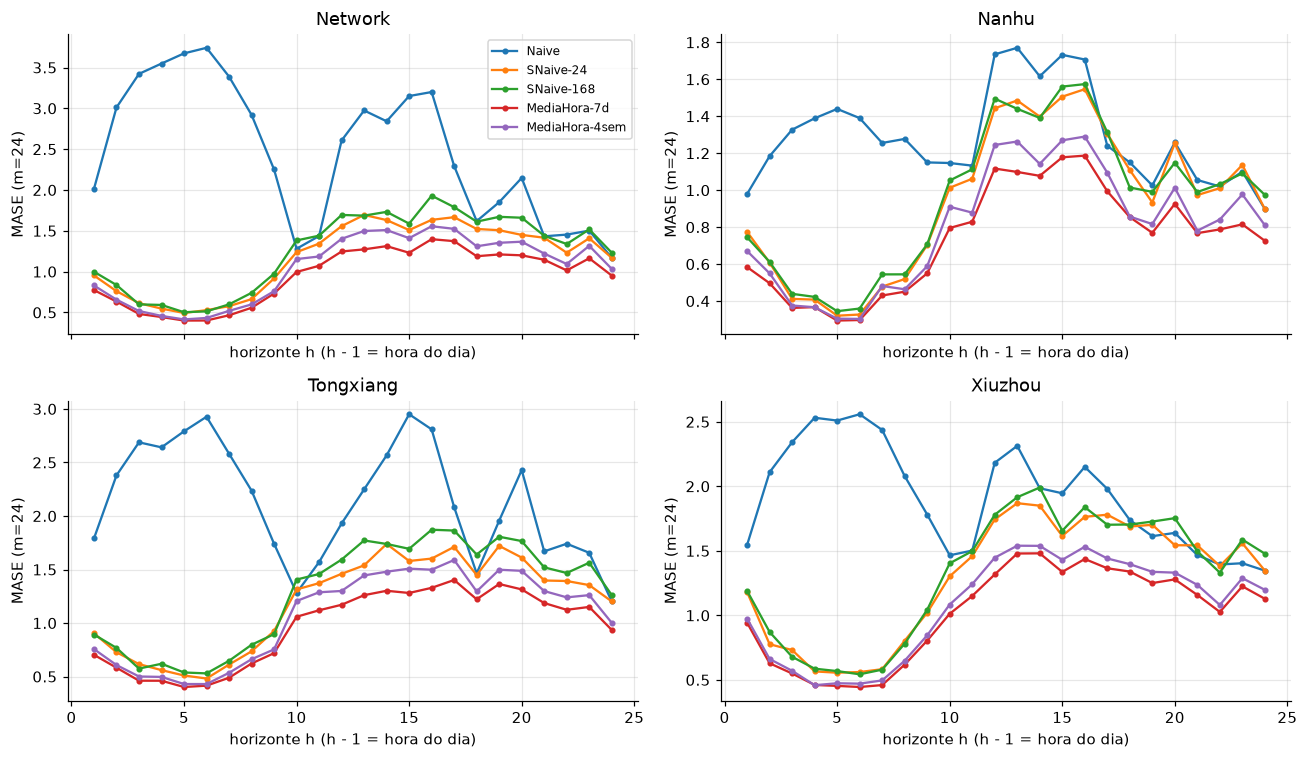

In [24]:
mase_fold = res_f.pivot_table(index=["level", "model"], columns="fold", values="MASE")
display(mase_fold.round(3))

mean_h = res_h.groupby(["level", "model", "horizon"])["MASE"].mean().unstack("model")
wins = mean_h.idxmin(axis=1).groupby("level").value_counts().unstack(fill_value=0)
print("Nº de horizontes (em 24) em que cada baseline tem o menor MASE médio:")
display(wins)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, lv in zip(axes.ravel(), LEVELS):
    for m in BASELINES:
        ax.plot(HORIZONS, mean_h.loc[lv, m], marker="o", ms=3, label=m)
    ax.set(title=lv, xlabel="horizonte h (h - 1 = hora do dia)", ylabel="MASE (m=24)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Leitura.** Como a emissão é à meia-noite, o horizonte $h$ identifica a **hora do dia** ($h-1$). O erro destas *baselines* varia sobretudo com o nível de procura de cada hora (mais alto de dia) e não com a distância ao último dado, porque nenhuma usa as últimas horas. A MédiaHora-7d tem o menor MASE em 23 ou 24 dos 24 horizontes em cada nível e é a melhor em todos os 16 pares *fold* × nível. O F2 (2021-Q1) é o *fold* mais fácil em todos os níveis; o pior é o F1 em três níveis e o F4 em Xiuzhou. Um modelo que use as últimas horas observadas deverá ganhar sobretudo nos primeiros horizontes.

In [25]:
ref = summary.loc[summary.groupby("level")["MASE"].idxmin(), ["level", "model", "MASE", "MASE_pior_fold"]].set_index("level")
ref.columns = ["baseline de referência", "MASE médio", "MASE pior fold"]
display(ref.round(3))
REFERENCE = ref["baseline de referência"].to_dict()

,baseline de referência,MASE médio,MASE pior fold
level,,,
Nanhu,MediaHora-7d,0.740,0.874
Network,MediaHora-7d,0.944,1.031
Tongxiang,MediaHora-7d,0.962,1.127
Xiuzhou,MediaHora-7d,1.015,1.163


### 5.4 Regras de comparação e seleção (fixadas antes dos modelos)

1. Todo o modelo é comparado com a **baseline de referência** de cada nível (tabela acima), nas mesmas origens, e com o mesmo MASE.
2. Um modelo só é considerado melhor se reduzir o MASE médio e **o fizer em pelo menos 3 dos 4 *folds*** de validação, em cada nível relevante.
3. Reporta-se sempre MAE, RMSE e MASE por **horizonte**, por **fold** e por **nível**, mais as métricas de pico e o custo computacional.
4. O **teste final é avaliado uma única vez**, com o modelo, os hiperparâmetros e o pré-processamento já congelados.
5. Uma variável meteorológica ou de calendário só entra no modelo final se melhorar a validação. O experimento com meteorologia do próprio dia (oráculo) serve apenas para medir o valor da informação perfeita e **não participa na seleção**.
6. **Sensibilidade do teste.** Nanhu perde postos em 2021-09-28 e em 2021-12-13 (secção 3.1), e ambas as quebras afetam o teste. Além do resultado no teste completo (que é o resultado principal), reporta-se o resultado sem os 14 dias seguintes a cada quebra (`SENS_DAYS`). Esta leitura é só informativa e **nunca serve para selecionar modelos**.

## 6. Exportação dos artefactos para as Tasks seguintes

In [26]:
series_out = hourly.copy()
series_out["hour_of_day"] = series_out.index.hour
series_out["day_of_week"] = series_out.index.dayofweek
series_out["is_holiday"] = series_out.index.normalize().isin(HOLIDAY_DAYS).astype(int)
series_out.to_csv("hourly_series_task1.csv")
weather_daily.to_csv("daily_weather_task1.csv", index=False)

protocol = {
    "series": {
        "definition": "sessões com Start Time em [t, t+1h); índice = início da hora; Network = soma dos 3 distritos",
        "start": str(SERIES_START), "end": str(SERIES_END), "freq": "h", "n_hours": int(len(hourly)),
        "timezone": "hora local da China (UTC+8, sem hora de verão)", "levels": LEVELS,
        "missing_hours_policy": "horas sem sessões = procura zero (grelha completa preenchida com 0)",
        "excluded_sessions_before_start": int(dropped_edge),
    },
    "issuance": {
        "schedule": "diária às 00:00 (hora local)", "horizons": [1, 24],
        "target": "sessões iniciadas em [T0+h-1h, T0+h), h=1..24 (as 24 horas do dia D)",
        "history_available": "até à hora iniciada em T0-1h",
    },
    "strategy": {"statistical": "iterada, um ajuste por fold, estado atualizado diariamente", "machine_learning": "direta (um modelo por horizonte ou h como atributo)",
                 "levels": "previsão independente por nível; verificar coerência soma distritos vs. rede"},
    "splits": {
        "development": [str(SERIES_START.date()), str(DEV_END.date())],
        "folds": [{"name": f["name"], "train": list(f["train"]), "validation": list(f["val"]), "scheme": "janela expansiva"} for f in FOLDS],
        "test": list(TEST),
    },
    "metrics": {"primary": ["MAE", "RMSE", "MASE"], "mase_seasonal_period": 24,
                "mase_scale": "MAE in-sample do seasonal naive (m=24) na janela de treino de cada fold e nível",
                "complementary": ["acerto da hora de pico (+-1h)", "erro absoluto do pico diário", "tempo por origem"]},
    "baselines": list(BASELINES), "reference_baseline": REFERENCE,
    "selection_rule": "melhor MASE médio e melhor em >= 3 de 4 folds, por nível; teste avaliado uma única vez",
    "predictors_policy": {
        "historical": "lags L usáveis no horizonte h só se L >= h",
        "known_future": ["hora do dia", "dia da semana", "feriado oficial", "véspera/dia seguinte a feriado"],
        "weather": "valor diário por distrito; known_at = D+1 00:00; só desfasado >= 1 dia; meteorologia do dia D apenas como oráculo diagnóstico",
        "excluded": ["variáveis da transação (energia, custo, duração, fim)", "end_cause e is_*", "UserID"],
    },
    "capacity_breaks": CAPACITY_BREAKS,
    "test_sensitivity_exclusion_days": [str(d.date()) for d in SENS_DAYS],
    "holidays": [{"from": a, "to": b, "name": n} for a, b, n in HOLIDAY_RANGES],
}
with open("protocol_task1.json", "w", encoding="utf-8") as fh:
    json.dump(protocol, fh, ensure_ascii=False, indent=2, default=str)

for f in ["hourly_series_task1.csv", "daily_weather_task1.csv", "protocol_task1.json"]:
    print(f, f"{Path(f).stat().st_size / 1024:,.0f} KB")

hourly_series_task1.csv 622 KB
daily_weather_task1.csv 90 KB
protocol_task1.json 5 KB


## 7. Síntese

**Qualidade dos dados.** A série horária de 17 544 pontos está completa. As 480 horas a zero são procura real (noite e colapso de 2020). Foram retiradas 17 sessões de 2019-12-31. A meteorologia só existe com resolução diária. O problema operacional mais relevante são as **duas quebras de capacidade de Nanhu** (2021-09-28 e 2021-12-13, 4 postos cada), ambas a afetar o teste. As sessões de 0 kWh (12,4%) mantêm-se e não alteram a série de forma material.

**Padrões da procura.**
- Sazonalidade diária muito forte (força 0,68 a 0,88) e semanal fraca (cerca de 0,18).
- Dois choques de nível (Festival da Primavera de 2020, com COVID-19, e o de 2021) e crescimento desigual entre distritos, sobretudo em Xiuzhou.
- Feriados com +12% de procura em média (-14% no Festival da Primavera de 2021) e picos na véspera.
- Distritos pouco correlacionados entre si e meteorologia com sinal fraco (|ρ| ≤ 0,16).
- Contagens sobredispersas, com muitas horas a zero em Nanhu; estacionárias depois de diferenciação de 24 h.

**Protocolo fixado (antes de qualquer modelo).**
- *Emissão* diária às 00:00, horizontes de 1 a 24 h, previsão independente por nível (rede e 3 distritos).
- *Estratégia:* iterada nos modelos estatísticos, direta nos de aprendizagem automática.
- *Informação:* *lags* com $L \geq h$; calendário determinístico; meteorologia só até D-1; variáveis da transação excluídas.
- *Validação:* 4 *folds* trimestrais de janela expansiva (2020-Q4 a 2021-Q3); teste em 2021-Q4 avaliado uma única vez, mais uma sensibilidade sem os 14 dias a seguir a cada quebra de Nanhu.
- *Métricas:* MAE, RMSE e MASE ($m=24$), mais acerto e erro do pico e custo computacional; sem MAPE.
- *Baselines:* Naïve, SNaïve-24, SNaïve-168, MédiaHora-7d e MédiaHora-4sem; **referência = MédiaHora-7d** (MASE em validação: Nanhu 0,74, Rede 0,94, Tongxiang 0,96, Xiuzhou 1,02).
- *Regra de seleção:* melhor MASE médio e melhor em pelo menos 3 dos 4 *folds*.

**A validar antes de avançar:** o calendário de feriados (inserido manualmente) e o tratamento do período de COVID-19 (janeiro a março de 2020), que fica para a Task 2.